# Самостоятельная работа: языковая модель на Elman RNN

В этом ноутбуке требуется самостоятельно собрать словарную языковую
модель следующего слова. Учебный маршрут совпадает с подробным
примером, но все содержательные части реализации отмечены только
внутри кодовых ячеек «TODO(student)». Здесь используется отдельный
корпус русской классической литературы RuHeritage-Corpus, поэтому
данные, жанр и словарь не совпадают с примером.

## Маршрут самостоятельной работы

Выполняйте ячейки по порядку. В каждой спецификации указаны доступные
переменные, входы, ожидаемые формы и контрольная точка. Не вставляйте
готовое решение из примера: воспроизведите необходимые преобразования
самостоятельно. Индексы токенов являются входом модели, а целевые
индексы следующего токена — вторым аргументом функции потерь. Меток
классов документа в этой работе нет. Каждый этап имеет одну и ту же
структуру: цель, входы, действия, ожидаемый результат и контрольная
точка. Если проверка не пройдена, не переходите к следующему этапу.

## Этап 1. Настройка самостоятельного эксперимента

**Цель:** зафиксировать независимую от примера постановку. Константы
выбирают RuHeritage-Corpus, его каталог данных «data», закреплённую
ревизию и поле «text». Первые 1 200 документов этого *другого*
потока достаточны для учебного CPU-эксперимента.

**Результат этапа:** определены все размеры модели и специальные
индексы. **Проверьте:** PAD, UNK, BOS и EOS равны соответственно
0, 1, 2 и 3; «MAX_SEQUENCE_LENGTH» равна 32. Эти числа — часть
контракта следующих этапов: индекс 0 будет маскироваться в потере, а
размерности 128 и два рекуррентных слоя определяют формы параметров.

In [1]:
from __future__ import annotations

import copy
import math
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
DATASET_NAME = 'maxzt/RuHeritage-Corpus'
DATASET_REVISION = 'b2d01eaad3ddb119fe10c4cb17a86e47415a77cb'
DATASET_DATA_DIR = 'data'
TEXT_FIELD = 'text'
START_DOCUMENT = 0
MAX_DOCUMENTS = 1_200
MAX_WORDS_PER_DOCUMENT = 160
MAX_ORDINARY_WORDS = 6_000
MAX_SEQUENCE_LENGTH = 32
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 2
BATCH_SIZE = 64
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 12
PATIENCE = 3

SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = range(4)
DEVICE = torch.device('cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

/home/a/.venvs/mfdl/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


/home/a/.venvs/mfdl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Этап 2. Получение литературных документов и нормализация

**Цель:** превратить поток записей литературного корпуса в два списка
коротких последовательностей слов. **Входы:** «DATASET_NAME»,
«DATASET_REVISION», «DATASET_DATA_DIR», «TEXT_FIELD» и строка поля
«text». При загрузке передайте каталог данных «data», закреплённую
ревизию, «split='train'» и потоковый режим.

**Действие:** прочитайте только первые 1 200 документов, нормализуйте
текст, выделите русские словарные токены и оставьте не более 160 слов
на документ. Каждый шестой непустой документ направьте в валидацию.

Направляйте каждый шестой непустой документ в валидацию, остальные —
в обучение. Результат должен состоять из двух непустых списков
документов, где каждый документ является списком строк. Выведите
размеры и пример токенов. **Математический смысл:** в этот момент
строки превращаются в последовательности дискретных символов, но
ещё не в числа и не в векторы. **Контрольная точка:** не скачивается
весь корпус; обе части непусты; используется поле «text» именно
RuHeritage-Corpus. Если документ после нормализации слишком короток
для пары «вход — следующий токен», его разумно исключить до разбиения
на окна.

In [2]:
WORD_RE = re.compile(r"[а-яё]+(?:-[а-яё]+)?", flags=re.IGNORECASE)


def normalize_and_tokenize(text: str, max_words: int) -> list[str]:
    cleaned = " ".join(str(text).lower().split())
    return WORD_RE.findall(cleaned)[:max_words]


def load_documents(
    text_field: str,
    start_document: int,
    max_documents: int,
    max_words: int,
) -> tuple[list[list[str]], list[list[str]]]:
    # Потоковый режим: скачиваются только нужные записи, а не весь корпус.
    stream = load_dataset(
        DATASET_NAME,
        revision=DATASET_REVISION,
        data_dir=DATASET_DATA_DIR,
        split="train",
        streaming=True,
    )
    train_documents: list[list[str]] = []
    val_documents: list[list[str]] = []
    stop_document = start_document + max_documents

    for document_index, row in enumerate(stream):
        if document_index < start_document:
            continue
        if document_index >= stop_document:
            break
        tokens = normalize_and_tokenize(row.get(text_field, ""), max_words)
        if len(tokens) < 2:
            continue
        if (document_index - start_document) % 6 == 0:
            val_documents.append(tokens)
        else:
            train_documents.append(tokens)

    if not train_documents or not val_documents:
        raise RuntimeError("Не удалось получить обе части выборки.")
    return train_documents, val_documents


train_documents, val_documents = load_documents(
    TEXT_FIELD,
    START_DOCUMENT,
    MAX_DOCUMENTS,
    MAX_WORDS_PER_DOCUMENT,
)

print("Обучающих документов:", len(train_documents))
print("Валидационных документов:", len(val_documents))
print("Пример нормализованных токенов:", train_documents[0][:20])

Обучающих документов: 1000
Валидационных документов: 200
Пример нормализованных токенов: ['википроекты', 'данные', 'примечания', 'эпиграмма', 'метит', 'не', 'только', 'в', 'кн', 'шихматова', 'как', 'толкует', 'ее', 'л', 'н', 'майков', 'но', 'как', 'показывает', 'самое']


## Этап 3. Построение словаря и пар обучения

**Цель:** получить конечное индексное представление текста и
сформировать учебные примеры. **Доступные данные:** «train_documents», «val_documents»,
«SPECIAL_TOKENS», «MAX_ORDINARY_WORDS», «MAX_SEQUENCE_LENGTH».
**Требуется:** построить словарь только по обучающим документам с
резервированием индексов 0–3; незнакомые слова в обеих частях должны
переходить в «<unk>».

**Действие:** затем добавьте «<bos>» и «<eos>», разбейте длинный документ на окна не
длиннее 33 индексов и создайте пары «вход — цель» сдвигом на один
токен. Один объект Dataset должен вернуть два одномерных тензора
одинаковой длины, не превышающей 32. Контрольная точка: для пары
«[bos, a, b, eos]» вход равен «[bos, a, b]», а цель — «[a, b, eos]».
**Математический смысл:** второй массив — не метка документа, а
правильный класс следующего слова на каждой позиции. **Формы:** до
объединения в мини-пакет обе части одной пары одномерны, $(L)$, где
$1\leq L\leq32$; только функция объединения добавит ось $B$.

In [3]:
def build_vocabulary(
    documents: list[list[str]],
    max_ordinary_words: int,
) -> tuple[dict[str, int], list[str], Counter]:
    # Словарь строится только по обучающим документам: валидация не утекает.
    frequencies = Counter(token for document in documents for token in document)
    ordinary_tokens = [token for token, _ in frequencies.most_common(max_ordinary_words)]
    itos = SPECIAL_TOKENS + ordinary_tokens
    stoi = {token: index for index, token in enumerate(itos)}
    return stoi, itos, frequencies


stoi, itos, frequencies = build_vocabulary(train_documents, MAX_ORDINARY_WORDS)
VOCAB_SIZE = len(itos)

assert [stoi[token] for token in SPECIAL_TOKENS] == [PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX]
assert VOCAB_SIZE <= len(SPECIAL_TOKENS) + MAX_ORDINARY_WORDS


def encode_document(tokens: list[str]) -> list[int]:
    return [BOS_IDX] + [stoi.get(token, UNK_IDX) for token in tokens] + [EOS_IDX]


def make_language_pairs(
    documents: list[list[str]],
) -> list[tuple[torch.Tensor, torch.Tensor]]:
    pairs: list[tuple[torch.Tensor, torch.Tensor]] = []
    for document in documents:
        encoded = encode_document(document)
        # Окно на 33 индекса даёт пары длиной не более 32 после сдвига.
        for start in range(0, len(encoded) - 1, MAX_SEQUENCE_LENGTH):
            window = encoded[start : start + MAX_SEQUENCE_LENGTH + 1]
            if len(window) >= 2:
                pairs.append(
                    (
                        torch.tensor(window[:-1], dtype=torch.long),
                        torch.tensor(window[1:], dtype=torch.long),
                    )
                )
    return pairs


train_pairs = make_language_pairs(train_documents)
val_pairs = make_language_pairs(val_documents)

print("Размер словаря:", VOCAB_SIZE)
print("Пять самых частых слов:", frequencies.most_common(5))
print("Пар для обучения:", len(train_pairs), "| для валидации:", len(val_pairs))

example_input, example_target = torch.tensor([BOS_IDX, 4, 5, EOS_IDX])[:-1], torch.tensor(
    [BOS_IDX, 4, 5, EOS_IDX]
)[1:]
print("Проверка сдвига: вход", example_input.tolist(), "цель", example_target.tolist())
assert example_input.tolist() == [BOS_IDX, 4, 5]
assert example_target.tolist() == [4, 5, EOS_IDX]

Размер словаря: 6004
Пять самых частых слов: [('и', 6610), ('в', 6156), ('с', 2037), ('а', 1775), ('не', 1709)]
Пар для обучения: 5803 | для валидации: 1159
Проверка сдвига: вход [2, 4, 5] цель [4, 5, 3]


## Этап 4. Мини-пакет и маска технического заполнения

**Цель:** сделать пары одинаковой формы внутри одного мини-пакета.
**Вход:** список пар переменной длины. **Требуется:** написать Dataset
и функцию «collate_fn», которые вернут «input_ids» и «target_ids»
формы $(B,T)$ с $T\leq32$. Короткие строки дополните индексом
«PAD_IDX=0» справа. Создайте обучающий и валидационный DataLoader;
у обучающего допустимо перемешивание, у валидационного — нет.

**Результат:** первая полученная пара тензоров имеет одинаковую
двумерную форму, а заполнение присутствует только справа. Не путайте
«target_ids» с метками классов: это правильные следующие слова.
**Контрольная точка:** число позиций, где «target_ids» не равно
«PAD_IDX», положительно; именно эти позиции позднее войдут в среднюю
кросс-энтропию.

In [4]:
class LanguageModelDataset(Dataset):
    def __init__(self, pairs: list[tuple[torch.Tensor, torch.Tensor]]):
        self.pairs = pairs

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.pairs[index]


def collate_language_batch(batch):
    input_sequences, target_sequences = zip(*batch)
    input_ids = pad_sequence(input_sequences, batch_first=True, padding_value=PAD_IDX)
    target_ids = pad_sequence(target_sequences, batch_first=True, padding_value=PAD_IDX)
    return input_ids, target_ids


train_dataset = LanguageModelDataset(train_pairs)
val_dataset = LanguageModelDataset(val_pairs)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_language_batch,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_language_batch,
    num_workers=0,
)

sample_input_ids, sample_target_ids = next(iter(train_loader))
assert sample_input_ids.shape == sample_target_ids.shape
assert sample_input_ids.ndim == 2
assert sample_input_ids.shape[1] <= MAX_SEQUENCE_LENGTH

meaningful_positions = int((sample_target_ids != PAD_IDX).sum().item())
assert meaningful_positions > 0

print("Форма первой пары мини-пакета:", tuple(sample_input_ids.shape))
print("Входные индексы первой строки:", sample_input_ids[0, :10].tolist())
print("Целевые индексы первой строки:", sample_target_ids[0, :10].tolist())
print("Содержательных целевых позиций в мини-пакете:", meaningful_positions)

Форма первой пары мини-пакета: (64, 32)
Входные индексы первой строки: [2, 302, 1160, 145, 4, 602, 20, 671, 34, 4]
Целевые индексы первой строки: [302, 1160, 145, 4, 602, 20, 671, 34, 4, 1103]
Содержательных целевых позиций в мини-пакете: 1738


## Этап 5. Ручная рекуррентная сеть и прогноз логитов

**Цель:** реализовать отображение индексов слов в оценки следующего
слова. **Вход модели:** «input_ids» формы $(B,T)$ со значениями от 0 до
$V-1$. **Требуемая архитектура:**
$(B,T)\rightarrow\operatorname{Embedding}(V,128)\rightarrow
\operatorname{ElmanRNN}(128,2)\rightarrow\operatorname{Linear}(128,V)$.

**Действие:** реализуйте собственный рекуррентный блок с обучаемыми входными и
рекуррентными весами, смещением и функцией tanh. Затем реализуйте два
последовательных слоя и выходную линейную проекцию. Не используйте
готовый «nn.RNN». Контрольная точка одного прямого прохода:
эмбеддинги и состояния имеют форму $(B,T,128)$, логиты — $(B,T,V)$.
Логиты ещё не являются вероятностями: это $V$ вещественных оценок,
к которым функция потерь внутренне применит softmax.

**Порядок вычислений:** индекс выбирает строку таблицы эмбеддингов;
на каждом времени рекуррентный блок объединяет этот вектор с прежним
состоянием; верхний слой получает результат нижнего; линейный слой
создаёт оценки всех слов. Результат модели обязан зависеть от
параметров класса, иначе «backward()» не сможет найти направление
их изменения.

In [5]:
class ElmanRNNUnit(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.W_x = nn.Parameter(torch.empty(hidden_size, input_size))
        self.U_h = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b_h = nn.Parameter(torch.zeros(hidden_size))
        nn.init.xavier_uniform_(self.W_x)
        nn.init.orthogonal_(self.U_h)

    def forward(self, x_t: torch.Tensor, h_previous: torch.Tensor) -> torch.Tensor:
        # h_t = tanh(W x_t + U h_{t-1} + b)
        return torch.tanh(
            F.linear(x_t, self.W_x, self.b_h) + F.linear(h_previous, self.U_h)
        )


class ElmanRNN(nn.Module):
    def __init__(self, hidden_size: int, num_layers: int):
        super().__init__()
        self.hidden_size = hidden_size
        self.layers = nn.ModuleList(
            [ElmanRNNUnit(hidden_size, hidden_size) for _ in range(num_layers)]
        )

    def forward(self, embeddings: torch.Tensor) -> torch.Tensor:
        batch_size, steps, _ = embeddings.shape
        states = [
            embeddings.new_zeros(batch_size, self.hidden_size) for _ in self.layers
        ]
        outputs = []
        for time_index in range(steps):
            layer_input = embeddings[:, time_index, :]
            updated_states = []
            for layer, previous_state in zip(self.layers, states):
                layer_input = layer(layer_input, previous_state)
                updated_states.append(layer_input)
            states = updated_states
            outputs.append(layer_input)
        return torch.stack(outputs, dim=1)


class ElmanLanguageModel(nn.Module):
    def __init__(self, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBEDDING_DIM, padding_idx=PAD_IDX)
        self.rnn = ElmanRNN(HIDDEN_DIM, NUM_LAYERS)
        self.output = nn.Linear(HIDDEN_DIM, vocab_size)

    def forward(self, input_ids: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_ids)
        hidden_states = self.rnn(embeddings)
        return self.output(hidden_states)


model = ElmanLanguageModel(VOCAB_SIZE).to(DEVICE)

with torch.no_grad():
    diagnostic_logits = model(sample_input_ids.to(DEVICE))

assert diagnostic_logits.shape == (
    sample_input_ids.shape[0],
    sample_input_ids.shape[1],
    VOCAB_SIZE,
)
print("Логиты:", tuple(diagnostic_logits.shape))
print("Параметров в модели:", sum(p.numel() for p in model.parameters()))

Логиты: (64, 32, 6004)
Параметров в модели: 1608820


## Этап 6. Обучение по сдвинутым целям и ранняя остановка

**Цель:** изменить параметры так, чтобы правильный следующий токен
получал больший логит. **Входы каждого шага:** «input_ids» и «target_ids» формы $(B,T)$.
**Требуется:** получить логиты $(B,T,V)$, развернуть логиты и цели по
позициям, создать «CrossEntropyLoss(ignore_index=PAD_IDX)» и AdamW.
Усредняйте потерю только по незаполненным позициям; сохраняйте лучшее
состояние по валидационной потере; завершайте обучение после трёх эпох
без улучшения, но не позже 12-й.

**Порядок вычислений:** в обучающем цикле очистите градиенты, выполните прямой проход,
«backward()» и «step()». На валидации обновление параметров запрещено.
Храните списки «history['loss']» и «history['val_loss']». Контрольная
точка: все значения конечны, а потеря обучения в целом снижается.
При вычислении итоговой эпохи суммируйте отрицательные логарифмы и
число реальных токенов по всем мини-пакетам отдельно: среднее средних
при разных длинах мини-пакетов дало бы смещённую оценку.

In [6]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, reduction="sum")
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)


def negative_log_likelihood(
    logits: torch.Tensor,
    target_ids: torch.Tensor,
) -> tuple[torch.Tensor, int]:
    vocab_dimension = logits.shape[-1]
    summed_nll = criterion(
        logits.reshape(-1, vocab_dimension),
        target_ids.reshape(-1),
    )
    token_count = int((target_ids != PAD_IDX).sum().item())
    if token_count == 0:
        raise RuntimeError("В мини-пакете нет содержательных целевых токенов.")
    return summed_nll, token_count


def run_epoch(loader: DataLoader, training: bool) -> float:
    model.train(training)
    total_nll = 0.0
    total_tokens = 0
    iterator = tqdm(loader, leave=False, disable=True)

    for input_ids, target_ids in iterator:
        input_ids = input_ids.to(DEVICE)
        target_ids = target_ids.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(input_ids)
            summed_nll, token_count = negative_log_likelihood(logits, target_ids)
            loss = summed_nll / token_count

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        total_nll += float(summed_nll.detach().cpu())
        total_tokens += token_count

    epoch_loss = total_nll / total_tokens
    if not math.isfinite(epoch_loss):
        raise FloatingPointError("Потеря не является конечным числом.")
    return epoch_loss


history = {"loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Эпоха {epoch:02d}: loss={train_loss:.4f}; val_loss={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Ранняя остановка: валидационная потеря не улучшалась.")
            break

if best_state is None:
    raise RuntimeError("Ни одно состояние модели не было сохранено.")
model.load_state_dict(best_state)

assert all(math.isfinite(value) for value in history["loss"])
assert all(math.isfinite(value) for value in history["val_loss"])
print("Лучшая валидационная потеря:", round(best_val_loss, 4))

Эпоха 01: loss=6.3152; val_loss=5.5489


Эпоха 02: loss=5.7592; val_loss=5.2260


Эпоха 03: loss=5.3989; val_loss=5.0023


Эпоха 04: loss=5.0996; val_loss=4.8455


Эпоха 05: loss=4.8420; val_loss=4.7163


Эпоха 06: loss=4.6089; val_loss=4.6367


... (2 outputs left out)

Эпоха 09: loss=4.0206; val_loss=4.4876


Эпоха 10: loss=3.8513; val_loss=4.4674


Эпоха 11: loss=3.6963; val_loss=4.4456


Эпоха 12: loss=3.5488; val_loss=4.4296
Лучшая валидационная потеря: 4.4296


## Этап 7. Оценка, перплексия и осмысленная интерпретация

**Цель:** проверить модель на данных, по которым не происходило
обновление параметров. **Вход:** лучшая обученная модель и валидационный DataLoader.
**Требуется:** вычислить среднюю кросс-энтропию по токенам и
перплексию $\exp(\mathcal L)$, построить графики «loss» и «val_loss»,
получить top-$k$ продолжений короткого русского запроса и выполнить
жадную генерацию до EOS или лимита.

Контрольная точка: перплексия — конечное положительное число; top-$k$
содержит слова из «itos»; цикл генерации имеет явный предел шагов.
В отчёте объясните, почему маленькая модель может выдавать частые, но
не всегда содержательные продолжения. Сопоставьте каждый top-$k$
прогноз с тем, что логиты последней позиции сначала превращаются в
распределение softmax, а затем сортируются по вероятности.

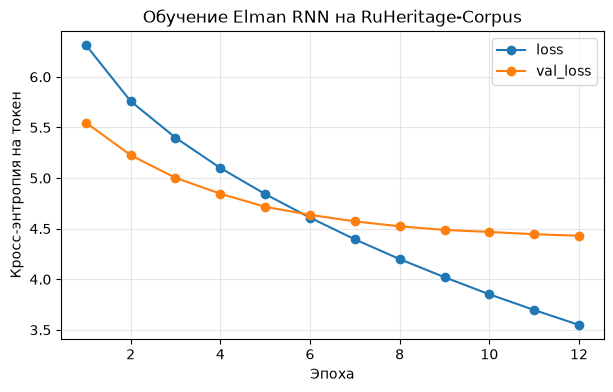

Валидационная потеря: 4.4296
Валидационная перплексия: 83.90
Запрос: 'и в с'
                   т: 0.0770
                   п: 0.0688
             нечаева: 0.0586
                   и: 0.0384
             пушкина: 0.0341
Жадная генерация: и в с т собрание сочинений в т м гихл том в году в году

Интерпретация: за 12 эпох потеря на обучении упала с 6.32 до 3.55, на валидации — с 5.55 до 4.43; перплексия 83.9 означает, что модель в среднем сомневается между десятками вариантов следующего слова.
Модель выучила частотную статистику корпуса, но не длинные зависимости: контекст ограничен 32 токенами, скрытое состояние сжимает всю историю в 128 чисел, словарь обрезан до 6004 слов, а документы урезаны до 160 слов. Поэтому top-k продолжения — частые слова и связки, а не осмысленные фразы. Служебные токены в выводе скрыты: <unk> был бы самым вероятным ответом, так как редкие слова корпуса не попали в словарь.


In [7]:
final_val_loss = run_epoch(val_loader, training=False)
perplexity = math.exp(min(final_val_loss, 20.0))
assert math.isfinite(perplexity) and perplexity > 0

plt.figure(figsize=(7, 4))
epochs = range(1, len(history["loss"]) + 1)
plt.plot(epochs, history["loss"], marker="o", label="loss")
plt.plot(epochs, history["val_loss"], marker="o", label="val_loss")
plt.xlabel("Эпоха")
plt.ylabel("Кросс-энтропия на токен")
plt.title("Обучение Elman RNN на RuHeritage-Corpus")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"Валидационная потеря: {final_val_loss:.4f}")
print(f"Валидационная перплексия: {perplexity:.2f}")


def prompt_to_ids(prompt: str) -> list[int]:
    tokens = normalize_and_tokenize(prompt, MAX_SEQUENCE_LENGTH - 1)
    return [BOS_IDX] + [stoi.get(token, UNK_IDX) for token in tokens]


SPECIAL_INDICES = [PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX]


def hide_special_tokens(logits: torch.Tensor) -> torch.Tensor:
    # Служебные токены не должны попадать в осмысленные продолжения:
    # <unk> в корпусе частый просто из-за урезанного словаря.
    masked = logits.clone()
    masked[..., SPECIAL_INDICES] = float("-inf")
    return masked


@torch.no_grad()
def top_k_next_words(prompt: str, k: int = 5):
    model.eval()
    input_ids = torch.tensor([prompt_to_ids(prompt)], dtype=torch.long, device=DEVICE)
    logits = model(input_ids)
    probabilities = torch.softmax(hide_special_tokens(logits[0, -1]), dim=-1)
    values, indices = torch.topk(probabilities, k=k)
    return [(itos[index.item()], value.item()) for value, index in zip(values, indices)]


@torch.no_grad()
def greedy_generate(prompt: str, max_new_tokens: int = 12) -> str:
    model.eval()
    generated_ids = prompt_to_ids(prompt)
    for _ in range(max_new_tokens):
        model_input = torch.tensor([generated_ids], dtype=torch.long, device=DEVICE)
        logits = hide_special_tokens(model(model_input)[0, -1])
        next_id = int(torch.argmax(logits).item())
        if next_id == EOS_IDX:
            break
        generated_ids.append(next_id)
    visible_tokens = [
        itos[index]
        for index in generated_ids
        if index not in {PAD_IDX, BOS_IDX, EOS_IDX}
    ]
    return " ".join(visible_tokens)


prompt = " ".join(word for word, _ in frequencies.most_common(3))
print("Запрос:", repr(prompt))
for token, probability in top_k_next_words(prompt, k=5):
    print(f"  {token:>18s}: {probability:.4f}")
print("Жадная генерация:", greedy_generate(prompt))

print()
first_loss = history["loss"][0]
last_loss = history["loss"][-1]
first_val = history["val_loss"][0]
last_val = history["val_loss"][-1]
print(
    f"Интерпретация: за {len(history['loss'])} эпох потеря на обучении упала "
    f"с {first_loss:.2f} до {last_loss:.2f}, на валидации — с {first_val:.2f} "
    f"до {last_val:.2f}; перплексия {perplexity:.1f} означает, что модель "
    "в среднем сомневается между десятками вариантов следующего слова.\n"
    "Модель выучила частотную статистику корпуса, но не длинные зависимости: "
    "контекст ограничен 32 токенами, скрытое состояние сжимает всю историю в "
    "128 чисел, словарь обрезан до 6004 слов, а документы урезаны до 160 слов. "
    "Поэтому top-k продолжения — частые слова и связки, а не осмысленные фразы. "
    "Служебные токены в выводе скрыты: <unk> был бы самым вероятным ответом, "
    "так как редкие слова корпуса не попали в словарь."
)

## Этап 8. Самопроверка перед сдачей

- Использован RuHeritage-Corpus, его поле «text», каталог данных
  «data» и закреплённая ревизия.
- Словарь построен только по обучающей части; индексы PAD, UNK, BOS,
  EOS равны 0, 1, 2, 3.
- «input_ids» и «target_ids» имеют форму $(B,T)$, $T\leq32$.
- Эмбеддинги и скрытые состояния имеют форму $(B,T,128)$; логиты —
  $(B,T,V)$.
- PAD исключён из кросс-энтропии, а не заменён на обычную цель.
- Потери и перплексия конечны; сохранена лучшая валидационная модель.
- В коде нет TensorFlow, Keras и готового «nn.RNN».